In [2]:
%pip install pandas

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl (9.8 MB)
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.7 MB 6.0 MB/s eta 0:00:03
   -------- ------------------------------- 2.6/12.7 MB 10.1 MB/s eta 0:00:01
   --------------- ------------------------ 5.0/12.7 MB 11.6 MB/s eta 0:00:01
   ----------------------- ---------------- 7.6/12.7 MB 11.1 MB/s eta 0:00:01
   -------------------------------- ------- 10.2/12.7 MB 11.5 MB/s eta 0:00:01
   -------------------------------------- - 12.3/12.7 MB 11.3 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 10.6 MB/s  0:00:01

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   -------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.4


In [5]:
import pandas as pd

df = pd.read_csv("Data_Cleaning_Visualization_Practice.csv")

print(df.head())
print(df.shape)
print(df.info())

  Order_ID  Order_Date Customer_Name Region       Product     Category  \
0  SO-0001  2026-01-04  Aarav Sharma  North        Laptop  Electronics   
1  SO-0002  2026-02-07    Diya Patel  South    Headphones  Electronics   
2  SO-0003  2026-03-10   Rohan Gupta   East  Office Chair    Furniture   
3  SO-0004  2026-04-13    Meera Iyer   West     Desk Lamp    Furniture   
4  SO-0005  2026-05-16   Kabir Singh  North  Notebook Set   Stationery   

   Quantity  Unit_Price  Discount  Total_Sales Payment_Method  Sales_Rep  
0         2         650      0.05       1235.0           Card   A. Mehta  
1         3          85      0.10        229.5            UPI     B. Roy  
2         4         220      0.15        748.0           Cash    C. Shah  
3         5          45      0.00        225.0  Bank Transfer  D. Kapoor  
4         6          18      0.05        102.6           Card  E. Joseph  
(153, 12)
<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 12 columns):
 

In [6]:
display(df.head())
display(df.tail())

print("Rows and columns:", df.shape)

print("Column names:", df.columns.tolist())

display(df.describe())

,Order_ID,Order_Date,Customer_Name,Region,Product,Category,Quantity,Unit_Price,Discount,Total_Sales,Payment_Method,Sales_Rep
0,SO-0001,2026-01-04,Aarav Sharma,North,Laptop,Electronics,2,650,0.05,1235.0,Card,A. Mehta
1,SO-0002,2026-02-07,Diya Patel,South,Headphones,Electronics,3,85,0.10,229.5,UPI,B. Roy
2,SO-0003,2026-03-10,Rohan Gupta,East,Office Chair,Furniture,4,220,0.15,748.0,Cash,C. Shah
3,SO-0004,2026-04-13,Meera Iyer,West,Desk Lamp,Furniture,5,45,0.00,225.0,Bank Transfer,D. Kapoor
4,SO-0005,2026-05-16,Kabir Singh,North,Notebook Set,Stationery,6,18,0.05,102.6,Card,E. Joseph


,Order_ID,Order_Date,Customer_Name,Region,Product,Category,Quantity,Unit_Price,Discount,Total_Sales,Payment_Method,Sales_Rep
148,SO-0149,2026-05-16,Kabir Singh,North,Notebook Set,Stationery,6,18,0.05,102.6,Card,D. Kapoor
149,SO-0150,2026-06-19,Ananya Das,South,Wireless Mouse,Electronics,1,32,0.10,28.8,UPI,E. Joseph
150,SO-0151,2026-03-31,NaN,North,Laptop,Electronics,2,650,0.10,1170.0,Card,A. Mehta
151,SO-0152,31/04/2026,Rohan Gupta,South,Headphones,Electronics,-1,85,0.00,-85.0,UPI,B. Roy
152,SO-0047,2026-02-07,Sanjay Kumar,East,Water Bottle,Lifestyle,6,15,0.15,76.5,Cash,B. Roy


Rows and columns: (153, 12)
Column names: ['Order_ID', 'Order_Date', 'Customer_Name', 'Region', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Discount', 'Total_Sales', 'Payment_Method', 'Sales_Rep']


,Quantity,Unit_Price,Discount,Total_Sales
count,153.000000,153.000000,153.000000,153.000000
mean,3.477124,143.529412,0.075163,489.475817
std,1.751259,206.553901,0.055938,848.410361
min,-1.000000,15.000000,0.000000,-85.000000
25%,2.000000,32.000000,0.050000,68.400000
50%,3.000000,55.000000,0.100000,144.000000
75%,5.000000,220.000000,0.100000,382.500000
max,6.000000,650.000000,0.150000,3705.000000


In [7]:

import pandas as pd
import numpy as np

df_clean = df.copy()

text_cols = df_clean.select_dtypes(include=["object", "str"]).columns

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

for col in ["Region", "Product", "Category", "Payment_Method"]:
    df_clean[col] = df_clean[col].str.title()

df_clean["Customer_Name"] = (
    df_clean["Customer_Name"].fillna("Unknown")
)

df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Exact duplicate rows:",
      df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

invalid_sales = (
    (df_clean["Quantity"] <= 0) |
    (df_clean["Unit_Price"] < 0) |
    (df_clean["Total_Sales"] < 0)
)

print("Invalid sales records:", invalid_sales.sum())

display(df_clean.loc[invalid_sales])

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nRepeated Order_ID rows:")
display(
    df_clean[df_clean["Order_ID"].duplicated(keep=False)]
)

df_clean.to_csv("sales_cleaned_review.csv", index=False)

print("\nWorking copy saved as sales_cleaned_review.csv")


Exact duplicate rows: 1
Invalid sales records: 1


,Order_ID,Order_Date,Customer_Name,Region,Product,Category,Quantity,Unit_Price,Discount,Total_Sales,Payment_Method,Sales_Rep
151,SO-0152,NaT,Rohan Gupta,South,Headphones,Electronics,-1,85,0.0,-85.0,Upi,B. Roy



Missing values:
Order_ID          0
Order_Date        1
Customer_Name     0
Region            0
Product           0
Category          0
Quantity          0
Unit_Price        0
Discount          0
Total_Sales       0
Payment_Method    0
Sales_Rep         0
dtype: int64

Repeated Order_ID rows:


,Order_ID,Order_Date,Customer_Name,Region,Product,Category,Quantity,Unit_Price,Discount,Total_Sales,Payment_Method,Sales_Rep



Working copy saved as sales_cleaned_review.csv


In [8]:

df_final = df_clean.copy()

df_final = df_final.dropna(subset=["Order_Date"])

df_final = df_final[
    (df_final["Quantity"] > 0) &
    (df_final["Unit_Price"] >= 0) &
    (df_final["Total_Sales"] >= 0)
].copy()

print("Duplicate Order IDs:", df_final["Order_ID"].duplicated().sum())

print("Final dataset shape:", df_final.shape)
print("\nMissing values:")
print(df_final.isna().sum())

df_final.to_csv("cleaned_sales_data.csv", index=False)

print("\nFinal cleaned dataset saved successfully!")


Duplicate Order IDs: 0
Final dataset shape: (151, 12)

Missing values:
Order_ID          0
Order_Date        0
Customer_Name     0
Region            0
Product           0
Category          0
Quantity          0
Unit_Price        0
Discount          0
Total_Sales       0
Payment_Method    0
Sales_Rep         0
dtype: int64

Final cleaned dataset saved successfully!


In [9]:

import matplotlib.pyplot as plt

df_final.groupby("Region")["Total_Sales"].sum().plot(kind="bar")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

plt.hist(df_final["Total_Sales"], bins=15, edgecolor="black")
plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

sales = df_final.groupby("Order_Date")["Total_Sales"].sum().sort_index()
plt.figure(figsize=(10, 5))
plt.plot(sales.index, sales.values, marker="o")
plt.title("Sales Trend Over Time")
plt.xlabel("Order Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.scatter(df_final["Quantity"], df_final["Total_Sales"])
plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'matplotlib'

In [10]:
%pip install matplotlib


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 1.5 MB/s eta 0:00:06
   ---- ----------------------------------- 1.0/9.5 MB 1.9 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.5 MB 2.4 MB/s eta 0:00:04
   ----------- ---------------------------- 2.6/9.5 MB 2.8 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.5 MB 3.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 3.4 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.5 MB 3.9 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 4.0 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 4.5 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 4.5 MB/s  0:00:02
Using cached cycler-0.12.1-py3-none-any.w

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [13]:
import matplotlib.pyplot as plt


In [14]:
print("Matplotlib imported successfully!")

Matplotlib imported successfully!


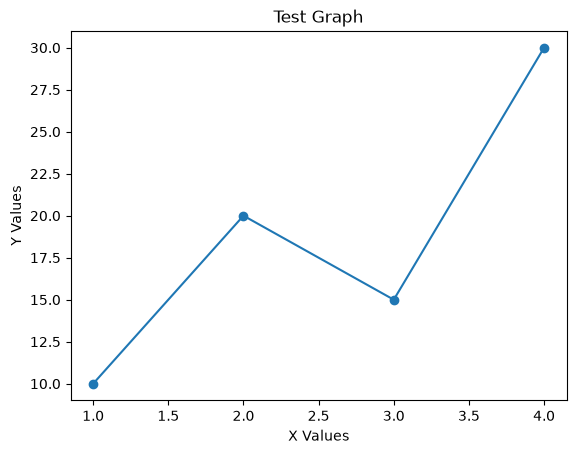

In [15]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3, 4], [10, 20, 15, 30], marker="o")
plt.title("Test Graph")
plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.show()

In [16]:

print("Total Orders:", df_final["Order_ID"].nunique())
print("Total Sales:", df_final["Total_Sales"].sum())
print("Average Sales:", round(df_final["Total_Sales"].mean(), 2))
print("Total Quantity Sold:", df_final["Quantity"].sum())

print("\nSales by Region:")
display(
    df_final.groupby("Region")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("\nBest-Selling Products by Quantity:")
display(
    df_final.groupby("Product")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

Total Orders: 151
Total Sales: 74898.29999999999
Average Sales: 496.02
Total Quantity Sold: 527

Sales by Region:


Region
North    48198.8
East     15130.0
South     5944.5
West      5625.0
Name: Total_Sales, dtype: float64


Best-Selling Products by Quantity:


Product
Notebook Set      78
Laptop            76
Office Chair      76
Water Bottle      72
Desk Lamp         59
Headphones        57
Wireless Mouse    55
Backpack          54
Name: Quantity, dtype: int64